In [1]:
import os

racine = "/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2"

for split in ["Train", "Val", "Test"]:
    chemin_split = os.path.join(racine, split)
    print(f"\n=== {split} ===")
    for classe in sorted(os.listdir(chemin_split)):
        chemin_classe = os.path.join(chemin_split, classe)
        if os.path.isdir(chemin_classe):
            n = len(os.listdir(chemin_classe))
            print(f"  {classe}: {n} éléments")




=== Train ===
  fake: 40536 éléments
  real: 40288 éléments

=== Val ===
  fake: 5068 éléments
  real: 5036 éléments

=== Test ===
  fake: 5067 éléments
  real: 5036 éléments


In [2]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
import os, random

racine = "/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2"

for split in ["Train", "Val", "Test"]:
    for classe in ["real", "fake"]:
        dossier = os.path.join(racine, split, classe)
        fichiers = sorted(os.listdir(dossier))
        print(f"\n{split}/{classe} ({len(fichiers)} fichiers) :")
        print("  début de liste :", fichiers[:3])
        print("  au hasard      :", random.sample(fichiers, 5))


Train/real (40288 fichiers) :
  début de liste : ['00000_face_0.jpg', '00000_face_1.jpg', '00000_face_10.jpg']
  au hasard      : ['id41_0005_face_18961.jpg', 'id36_0000_face_15261.jpg', 'id33_0000_face_13569.jpg', 'id28_0000_face_10188.jpg', '00268_face_15195.jpg']

Train/fake (40536 fichiers) :
  début de liste : ['id0_id16_0000_face_0.jpg', 'id0_id16_0000_face_1.jpg', 'id0_id16_0000_face_2.jpg']
  au hasard      : ['id17_id20_0002_face_3836.jpg', 'id23_id37_0002_face_12585.jpg', 'id31_id37_0002_face_24180.jpg', 'id25_id22_0002_face_13926.jpg', 'id41_id44_0004_face_34360.jpg']

Val/real (5036 fichiers) :
  début de liste : ['00000_face_19.jpg', '00000_face_40.jpg', '00000_face_42.jpg']
  au hasard      : ['id29_0000_face_10765.jpg', '00091_face_5168.jpg', 'id13_0008_face_2653.jpg', '00218_face_12410.jpg', 'id5_0004_face_29831.jpg']

Val/fake (5068 fichiers) :
  début de liste : ['id0_id16_0001_face_12.jpg', 'id0_id16_0003_face_35.jpg', 'id0_id16_0004_face_37.jpg']
  au hasard      :

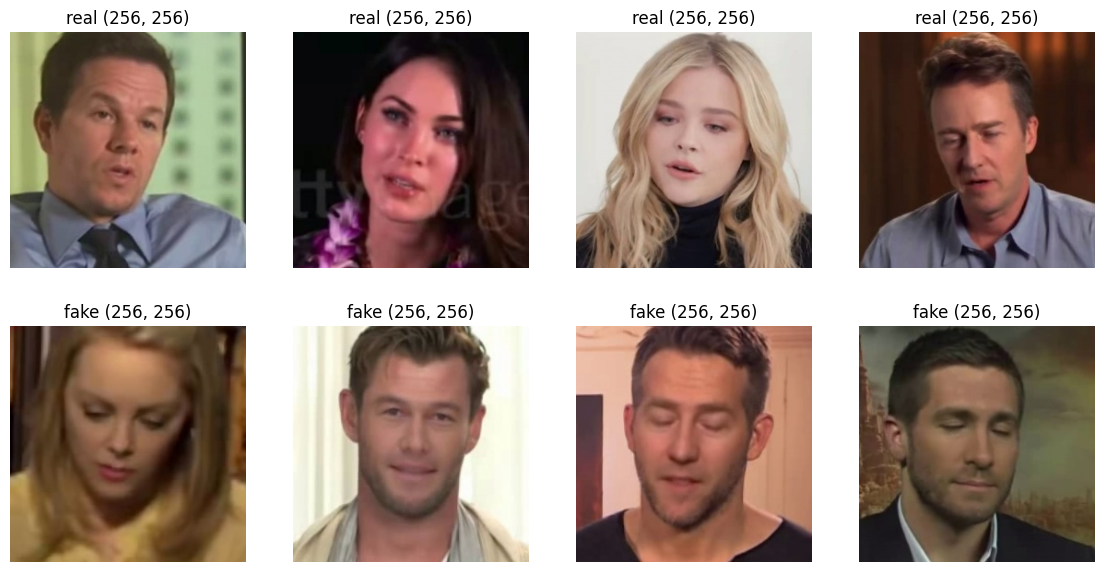

In [4]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, classe in enumerate(["real", "fake"]):
    dossier = os.path.join(racine, "Train", classe)
    for j, f in enumerate(random.sample(os.listdir(dossier), 4)):
        img = Image.open(os.path.join(dossier, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{classe} {img.size}")
        axes[i, j].axis("off")
plt.show()

In [5]:
import os
import pandas as pd

racine = "/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2"

lignes = []
for split in ["Train", "Val", "Test"]:
    for classe in ["real", "fake"]:
        dossier = os.path.join(racine, split, classe)
        for f in os.listdir(dossier):
            lignes.append({
                "path": os.path.join(dossier, f),
                "label": 1 if classe == "fake" else 0,   # 1 = fake, 0 = real
                "old_split": split,
                "video": f.split("_face_")[0],           # ex: id0_id16_0000
            })

df = pd.DataFrame(lignes)
print("Total images :", len(df))

Total images : 101031


In [6]:
# Combien de vidéos différentes, par classe ?
print(df.groupby("label")["video"].nunique())

# Combien d'images par vidéo ?
print(df.groupby("video").size().describe())

# Les vidéos qui sont dans plus d'un split = la fuite
nb_splits = df.groupby("video")["old_split"].nunique()
print("Vidéos au total             :", len(nb_splits))
print("Vidéos présentes dans >1 split :", (nb_splits > 1).sum())

label
0     889
1    5639
Name: video, dtype: int64
count    6528.000000
mean       15.476562
std        16.408324
min         1.000000
25%         9.000000
50%         9.000000
75%         9.000000
max       114.000000
dtype: float64
Vidéos au total             : 6528
Vidéos présentes dans >1 split : 5741


In [7]:
import os
import numpy as np
import pandas as pd

racine = "/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2"
SEED = 42

# 1) Reconstruire le tableau (une ligne par image)
lignes = []
for split in ["Train", "Val", "Test"]:
    for classe in ["real", "fake"]:
        dossier = os.path.join(racine, split, classe)
        for f in os.listdir(dossier):
            lignes.append({
                "rel_path": f"{split}/{classe}/{f}",   # chemin relatif au dossier Celeb_V2
                "label": 1 if classe == "fake" else 0, # 0 = real, 1 = fake
                "video": f.split("_face_")[0],
            })
df = pd.DataFrame(lignes)

# 2) Répartir les VIDÉOS, classe par classe
rng = np.random.RandomState(SEED)
video_vers_split = {}
for label in [0, 1]:
    videos = df[df.label == label]["video"].unique()
    rng.shuffle(videos)
    n = len(videos)
    n_train, n_val = int(0.8 * n), int(0.1 * n)
    for v in videos[:n_train]:
        video_vers_split[v] = "train"
    for v in videos[n_train:n_train + n_val]:
        video_vers_split[v] = "val"
    for v in videos[n_train + n_val:]:
        video_vers_split[v] = "test"

df["split"] = df["video"].map(video_vers_split)

In [8]:
# Plus aucune vidéo dans >1 split ?
print("Vidéos dans >1 split :", (df.groupby("video")["split"].nunique() > 1).sum())

# Répartition finale en images et en vidéos
print(pd.crosstab(df["split"], df["label"], margins=True))
print(df.groupby(["split", "label"])["video"].nunique().unstack())

# Sauvegarde
df.to_csv("/kaggle/working/split_par_video.csv", index=False)

Vidéos dans >1 split : 0
label      0      1     All
split                      
test    5082   5073   10155
train  40266  40532   80798
val     5012   5066   10078
All    50360  50671  101031
label    0     1
split           
test    90   565
train  711  4511
val     88   563


In [9]:
import tensorflow as tf
from tensorflow.keras import layers
import pandas as pd

RACINE = "/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2"
df = pd.read_csv("/kaggle/working/split_par_video.csv")

SEED = 42
IMG_SIZE = 128
BATCH = 64
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEED)

In [10]:
def charger(path, label):
    img = tf.io.read_file(path)                    # lit les octets du fichier
    img = tf.image.decode_jpeg(img, channels=3)    # JPEG -> tableau (256, 256, 3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, tf.cast(label, tf.float32)         # label 0.0 ou 1.0

In [11]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),                          # miroir gauche/droite
    layers.RandomRotation(0.05),                              # rotation d'environ ±18°
    layers.RandomBrightness(0.1, value_range=(0, 255)),       # luminosité ±10 %
    layers.RandomContrast(0.1),                               # contraste ±10 %
])

I0000 00:00:1793739363.574101      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793739363.577866      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [12]:
def make_ds(split, training):
    d = df[df.split == split]
    paths = (RACINE + "/" + d.rel_path).values
    labels = d.label.values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(d), seed=SEED)       # mélange l'ordre des images
    ds = ds.map(charger, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds("train", training=True)
val_ds   = make_ds("val",   training=False)
test_ds  = make_ds("test",  training=False)

Forme d'un batch : (64, 128, 128, 3) (64,)
Valeurs pixel : min 0.0 max 255.0


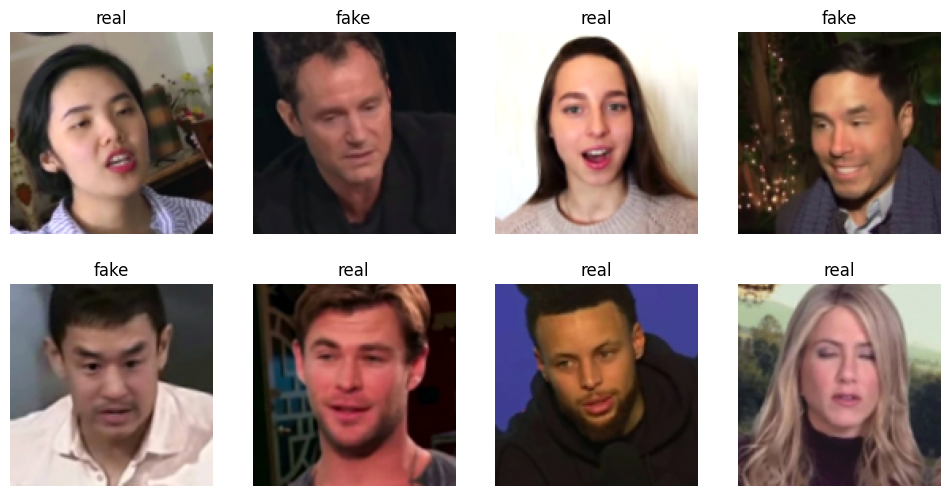

In [13]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))
print("Forme d'un batch :", images.shape, labels.shape)
print("Valeurs pixel : min", float(tf.reduce_min(images)), "max", float(tf.reduce_max(images)))

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title("fake" if labels[i] == 1 else "real")
    plt.axis("off")
plt.show()

In [14]:
from tensorflow.keras import layers, models, Input

def bloc(x, filtres):
    x = layers.Conv2D(filtres, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

inputs = Input((IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(1/255)(inputs)        # normalisation [0,255] -> [0,1]
for f in [32, 64, 128, 256]:
    x = bloc(x, f)
x = layers.GlobalAveragePooling2D()(x)     # (8,8,256) -> (256,)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name="cnn_simple")
model.summary()

Model: "cnn_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390,113 (1.49 MB)

 Trainable params: 389,153 (1.48 MB)

 Non-trainable params: 960 (3.75 KB)

In [15]:
import numpy as np
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

paths = (RACINE + "/" + df.rel_path).values

def lire(p):
    return np.asarray(Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))

X = np.empty((len(df), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
with ThreadPoolExecutor(8) as ex:
    for i, arr in enumerate(tqdm(ex.map(lire, paths), total=len(paths))):
        X[i] = arr
y = df.label.values.astype("float32")

# découper selon le split du CSV
masque = {s: (df.split.values == s) for s in ["train", "val", "test"]}
X_train, y_train = X[masque["train"]], y[masque["train"]]
X_val,   y_val   = X[masque["val"]],   y[masque["val"]]
X_test,  y_test  = X[masque["test"]],  y[masque["test"]]
del X
print(X_train.shape, X_val.shape, X_test.shape)

100%|██████████| 101031/101031 [13:01<00:00, 129.26it/s]


(80798, 128, 128, 3) (10078, 128, 128, 3) (10155, 128, 128, 3)


In [16]:
from tensorflow.keras import layers, models, Input

def bloc(x, filtres):
    x = layers.Conv2D(filtres, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

inputs = Input((IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(1/255)(inputs)
x = layers.RandomFlip("horizontal")(x)
x = layers.RandomRotation(0.05)(x)
x = layers.RandomBrightness(0.1, value_range=(0, 1))(x)
x = layers.RandomContrast(0.1)(x)
for f in [32, 64, 128, 256]:
    x = bloc(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = models.Model(inputs, outputs, name="cnn_simple")

In [17]:
import time
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])
t = time.time()
model.fit(X_train[:6400], y_train[:6400], batch_size=64, epochs=1, verbose=1)
print("100 steps en", round(time.time() - t), "s")

100/100 ━━━━━━━━━━━━━━━━━━━━ 15s 80ms/step - accuracy: 0.9887 - loss: 0.0309
100 steps en 16 s


In [18]:
from tensorflow.keras import callbacks

# Réexécute d'abord la cellule du modèle (étape 3) pour repartir de poids neufs.

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall"),
             tf.keras.metrics.AUC(name="auc")],
)

cb = [
    callbacks.BackupAndRestore("/kaggle/working/backup"),
    callbacks.ModelCheckpoint("/kaggle/working/cnn_simple.keras",
                              monitor="val_loss", save_best_only=True),
    callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=64, epochs=25, shuffle=True,
    callbacks=cb,
)

Epoch 1/25
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 113s 87ms/step - accuracy: 0.6026 - auc: 0.6416 - loss: 0.6794 - precision: 0.5959 - recall: 0.6453 - val_accuracy: 0.6810 - val_auc: 0.7496 - val_loss: 0.6150 - val_precision: 0.7262 - val_recall: 0.5865 - learning_rate: 0.0010
Epoch 2/25
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 109s 86ms/step - accuracy: 0.7267 - auc: 0.8025 - loss: 0.5385 - precision: 0.7150 - recall: 0.7569 - val_accuracy: 0.6641 - val_auc: 0.8221 - val_loss: 0.6483 - val_precision: 0.8724 - val_recall: 0.3887 - learning_rate: 0.0010
Epoch 3/25
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 109s 86ms/step - accuracy: 0.8060 - auc: 0.8872 - loss: 0.4233 - precision: 0.8007 - recall: 0.8166 - val_accuracy: 0.5361 - val_auc: 0.8023 - val_loss: 1.1204 - val_precision: 0.9578 - val_recall: 0.0807 - learning_rate: 0.0010
Epoch 4/25
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 109s 86ms/step - accuracy: 0.8642 - auc: 0.9389 - loss: 0.3168 - precision: 0.8615 - recall: 0.8689 - val_accuracy: 0.7988 - val_auc: 0.9320 - va

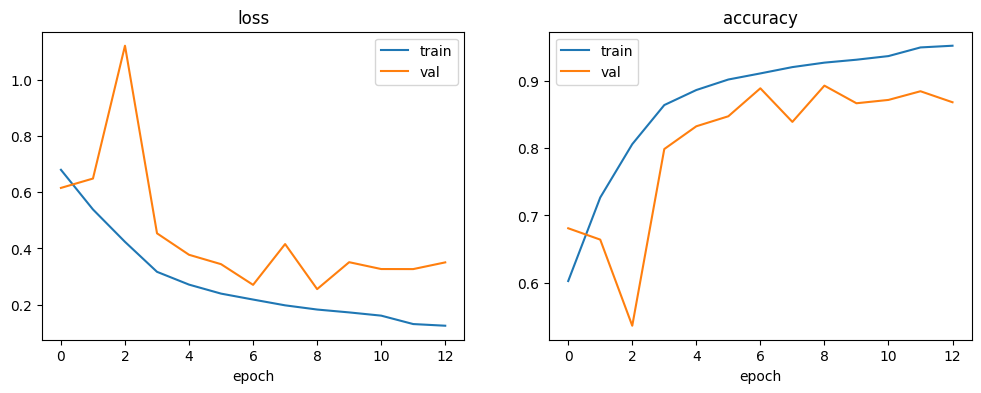

159/159 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step
              precision    recall  f1-score   support

        real      0.876     0.921     0.898      5082
        fake      0.917     0.870     0.893      5073

    accuracy                          0.896     10155
   macro avg      0.897     0.896     0.896     10155
weighted avg      0.897     0.896     0.896     10155



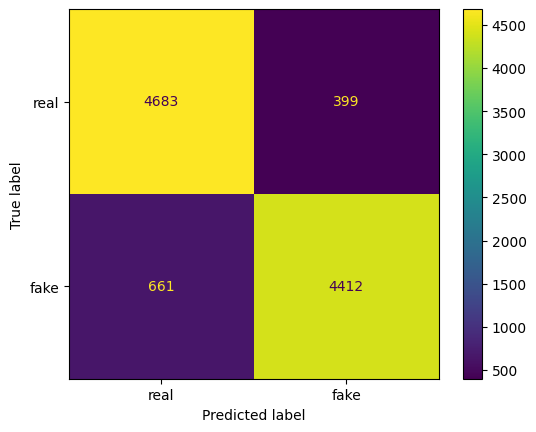

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pd.DataFrame(history.history).to_csv("/kaggle/working/cnn_simple_history.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[m], label="train")
    ax[i].plot(history.history["val_" + m], label="val")
    ax[i].set_title(m); ax[i].set_xlabel("epoch"); ax[i].legend()
plt.savefig("/kaggle/working/cnn_simple_courbes.png", dpi=150)
plt.show()

y_true = df[df.split == "test"].label.values
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=["real", "fake"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=["real", "fake"]).plot()
plt.savefig("/kaggle/working/cnn_simple_confusion.png", dpi=150)

In [20]:
for f in sorted(os.listdir(dossier)):          # au lieu de os.listdir(dossier)
    ...

videos = np.sort(df[df.label == label]["video"].unique())   # au lieu de .unique() seul

In [21]:
d = pd.read_csv("/kaggle/working/split_par_video.csv")
print(d.split.value_counts())

split
train    80798
test     10155
val      10078
Name: count, dtype: int64


In [22]:
#second entrainement
